In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Data splitting
from sklearn.model_selection import train_test_split

# Machine learning model
from sklearn.naive_bayes import MultinomialNB

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Download required NLTK resources
nltk.download('stopwords')

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jsite\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
# Dataset URL
dataset_url = (
    "https://raw.githubusercontent.com/"
    "justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
)

# Load dataset
df = pd.read_csv(
    dataset_url,
    sep='\t',
    header=None,
    names=['label', 'message']
)

print("Dataset loaded successfully!")

# Display first five records
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

Dataset loaded successfully!


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset Shape: (5572, 2)


In [3]:
# Dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nDataset Summary:")
display(df.describe(include='all'))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Count spam and ham messages
print("\nMessage Distribution:")
print(df['label'].value_counts())

Number of Rows: 5572
Number of Columns: 2

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Dataset Summary:


,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30



Missing Values:
label      0
message    0
dtype: int64

Duplicate Records: 403

Message Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
# Create a copy of the dataset
df = df.copy()

# Remove missing values
df.dropna(subset=['label', 'message'], inplace=True)

# Remove duplicate messages
df.drop_duplicates(subset=['label', 'message'], inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

# Convert labels into lowercase
df['label'] = df['label'].str.lower().str.strip()

# Keep only valid labels
df = df[df['label'].isin(['spam', 'ham'])]

# Convert labels into numerical values
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

print("Data cleaning completed!")

print("\nCleaned Dataset Shape:", df.shape)

display(df.head())

Data cleaning completed!

Cleaned Dataset Shape: (5169, 2)


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
# Initialize stopwords and stemmer
stop_words = set(stopwords.words('english'))

# Preserve negation words
stop_words = stop_words - {'no', 'not', 'nor'}

stemmer = PorterStemmer()

# Create text cleaning function
def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove numbers and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenize text
    words = text.split()

    # Remove stopwords and apply stemming
    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    # Join words back into a sentence
    return ' '.join(words)


# Apply text preprocessing
df['cleaned_message'] = df['message'].apply(clean_text)

print("Text preprocessing completed!")

display(df[['message', 'cleaned_message']].head(10))

Text preprocessing completed!


,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darl week no word back like fun st...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request mell mell oru minnaminungint nurun...
8,WINNER!! As a valued network customer you have...,winner valu network custom select receivea pri...
9,Had your mobile 11 months or more? U R entitle...,mobil month u r entitl updat latest colour mob...


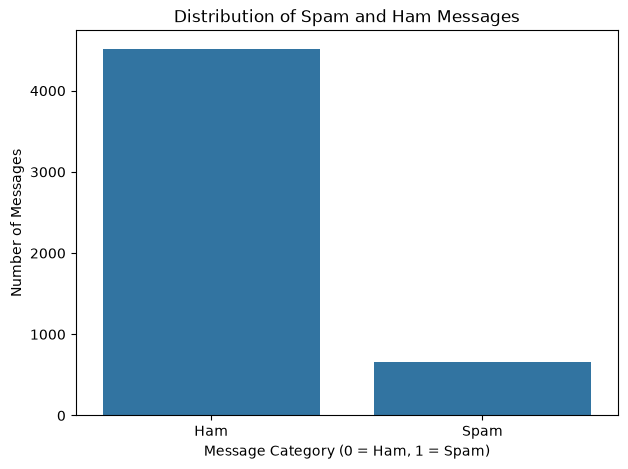

Ham Messages: 4516
Spam Messages: 653


In [6]:
# Count message categories
label_counts = df['label'].value_counts()

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='label'
)

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category (0 = Ham, 1 = Spam)")
plt.ylabel("Number of Messages")

plt.xticks(
    [0, 1],
    ['Ham', 'Spam']
)

plt.show()

print("Ham Messages:", label_counts.get(0, 0))
print("Spam Messages:", label_counts.get(1, 0))

Average Message Length:


,message_length,word_count
label,,
0,70.905890,14.239814
1,137.704441,23.739663


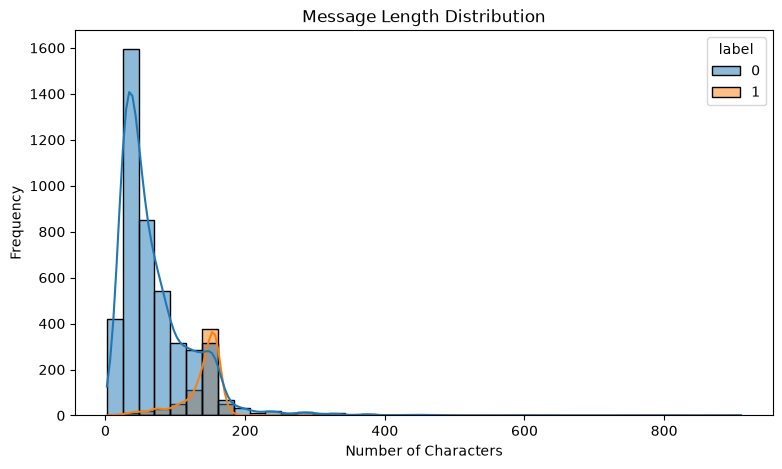

In [7]:
# Calculate message length
df['message_length'] = df['message'].apply(len)

# Calculate word count
df['word_count'] = df['message'].apply(
    lambda x: len(x.split())
)

# Compare average message length
print("Average Message Length:")
display(
    df.groupby('label')[['message_length', 'word_count']]
    .mean()
)

# Visualize message length
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins=40,
    kde=True
)

plt.title("Message Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.show()

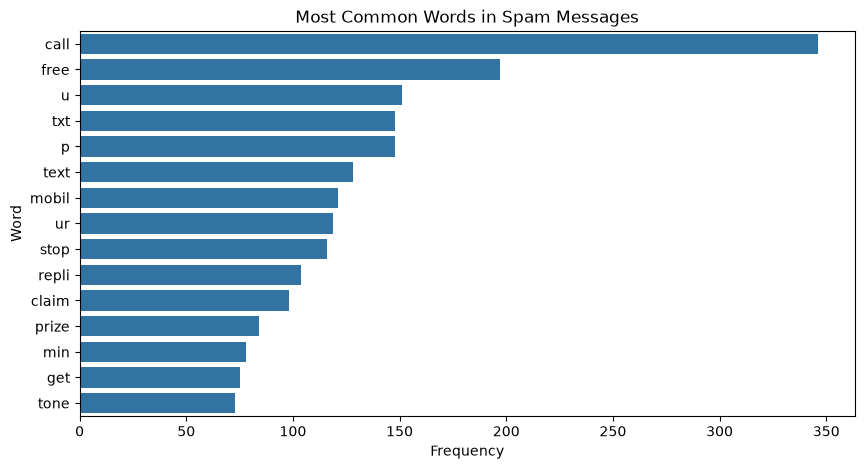

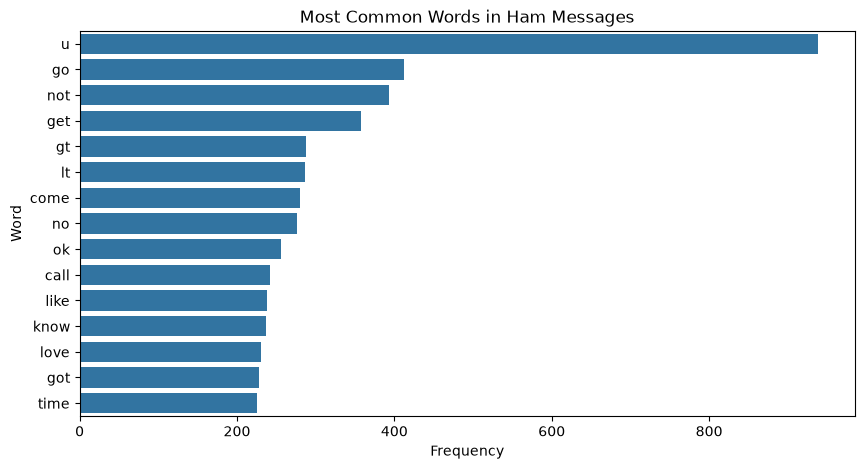

In [8]:
from collections import Counter

# Separate spam and ham messages
spam_words = ' '.join(
    df[df['label'] == 1]['cleaned_message']
).split()

ham_words = ' '.join(
    df[df['label'] == 0]['cleaned_message']
).split()

# Find the 15 most common words
spam_common = Counter(spam_words).most_common(15)
ham_common = Counter(ham_words).most_common(15)

# Convert into DataFrames
spam_df = pd.DataFrame(
    spam_common,
    columns=['Word', 'Frequency']
)

ham_df = pd.DataFrame(
    ham_common,
    columns=['Word', 'Frequency']
)

# Plot spam words
plt.figure(figsize=(10, 5))

sns.barplot(
    data=spam_df,
    x='Frequency',
    y='Word'
)

plt.title("Most Common Words in Spam Messages")
plt.show()

# Plot ham words
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ham_df,
    x='Frequency',
    y='Word'
)

plt.title("Most Common Words in Ham Messages")
plt.show()

In [9]:
# Define input features and target variable
X = df['cleaned_message']
y = df['label']

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Size:", len(X_train))
print("Testing Data Size:", len(X_test))

Training Data Size: 4135
Testing Data Size: 1034


In [10]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Fit only on training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing messages
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Feature Extraction Completed!")

print("Training Feature Shape:", X_train_tfidf.shape)
print("Testing Feature Shape:", X_test_tfidf.shape)

TF-IDF Feature Extraction Completed!
Training Feature Shape: (4135, 5000)
Testing Feature Shape: (1034, 5000)


In [11]:
from sklearn.preprocessing import MinMaxScaler
from scipy.sparse import hstack, csr_matrix

# Create numerical features from original messages
def extract_features(messages):

    features = []

    for message in messages:

        char_count = len(message)
        word_count = len(message.split())
        digit_count = sum(c.isdigit() for c in message)
        exclamation_count = message.count('!')

        features.append([
            char_count,
            word_count,
            digit_count,
            exclamation_count
        ])

    return np.array(features)


# Extract numerical features
X_train_extra = extract_features(
    df.loc[X_train.index, 'message']
)

X_test_extra = extract_features(
    df.loc[X_test.index, 'message']
)

# Scale numerical features between 0 and 1
scaler = MinMaxScaler()

X_train_extra = scaler.fit_transform(X_train_extra)
X_test_extra = scaler.transform(X_test_extra)

# Convert numerical features into sparse matrices
X_train_extra = csr_matrix(X_train_extra)
X_test_extra = csr_matrix(X_test_extra)

# Combine TF-IDF and numerical features
X_train_final = hstack([
    X_train_tfidf,
    X_train_extra
]).tocsr()

X_test_final = hstack([
    X_test_tfidf,
    X_test_extra
]).tocsr()

print("Feature Engineering Completed!")

print("Final Training Shape:", X_train_final.shape)
print("Final Testing Shape:", X_test_final.shape)

Feature Engineering Completed!
Final Training Shape: (4135, 5004)
Final Testing Shape: (1034, 5004)


In [12]:
# Initialize the Multinomial Naive Bayes model
model = MultinomialNB(alpha=0.5)

# Train the model
model.fit(
    X_train_final,
    y_train
)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [13]:
# Generate predictions on testing data
y_pred = model.predict(X_test_final)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

# Convert numerical labels into category names
results['Actual'] = results['Actual'].map({
    0: 'Ham',
    1: 'Spam'
})

results['Predicted'] = results['Predicted'].map({
    0: 'Ham',
    1: 'Spam'
})

print("Testing Results:")
display(results.head(15))

Testing Results:


,Actual,Predicted
0,Ham,Ham
1,Ham,Ham
2,Ham,Ham
3,Ham,Ham
4,Ham,Ham
5,Ham,Ham
6,Ham,Ham
7,Ham,Ham
8,Ham,Ham
9,Ham,Ham


In [14]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

# Display results
print("MODEL EVALUATION RESULTS")
print("-" * 40)

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")

MODEL EVALUATION RESULTS
----------------------------------------
Accuracy : 97.87 %
Precision: 99.1 %
Recall   : 83.97 %
F1-Score : 90.91 %


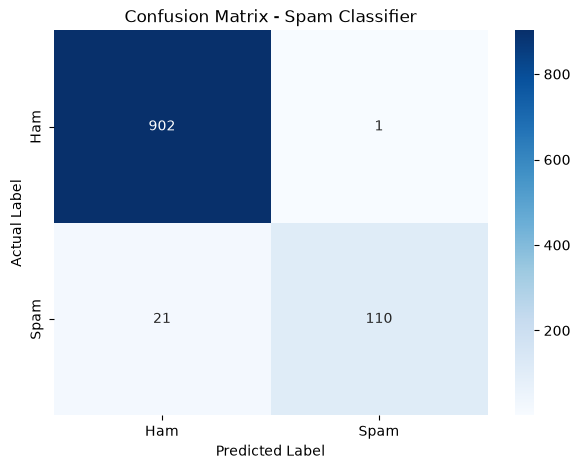

True Negative : 902
False Positive: 1
False Negative: 21
True Positive : 110


In [15]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("Confusion Matrix - Spam Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

# Display individual values
tn, fp, fn, tp = cm.ravel()

print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

In [16]:
# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam'],
    zero_division=0
)

print("DETAILED CLASSIFICATION REPORT")
print("=" * 50)

print(report)

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.99      0.84      0.91       131

    accuracy                           0.98      1034
   macro avg       0.98      0.92      0.95      1034
weighted avg       0.98      0.98      0.98      1034



In [17]:
# Create a function for predicting new messages

def predict_spam(message):

    # Clean the input message
    cleaned = clean_text(message)

    # Convert text into TF-IDF features
    text_vector = tfidf.transform([cleaned])

    # Extract numerical features
    extra_features = extract_features([message])

    # Scale numerical features
    extra_features = scaler.transform(extra_features)

    # Convert to sparse matrix
    extra_features = csr_matrix(extra_features)

    # Combine all features
    final_features = hstack([
        text_vector,
        extra_features
    ]).tocsr()

    # Predict message category
    prediction = model.predict(final_features)[0]

    # Calculate prediction probability
    probabilities = model.predict_proba(
        final_features
    )[0]

    spam_probability = probabilities[1] * 100

    if prediction == 1:
        result = "SPAM"
    else:
        result = "HAM (NOT SPAM)"

    print("\nMessage:", message)
    print("Prediction:", result)
    print("Spam Probability:", round(spam_probability, 2), "%")

    return result


# Test with sample messages
predict_spam(
    "Congratulations! You have won a free cash prize. Click here now!"
)

predict_spam(
    "Hey, are we meeting for lunch tomorrow?"
)


Message: Congratulations! You have won a free cash prize. Click here now!
Prediction: SPAM
Spam Probability: 96.39 %

Message: Hey, are we meeting for lunch tomorrow?
Prediction: HAM (NOT SPAM)
Spam Probability: 0.65 %


'HAM (NOT SPAM)'

In [18]:
# Create final evaluation table

evaluation_results = pd.DataFrame({
    'Evaluation Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],

    'Score (%)': [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

print("=" * 55)
print("         FINAL MODEL EVALUATION REPORT")
print("=" * 55)

display(evaluation_results.round(2))

print("\nModel Information")
print("-" * 55)

print("Project: Spam Email Classification")
print("Algorithm: Multinomial Naive Bayes")
print("Feature Extraction: TF-IDF Vectorization")
print("Additional Features: Message Length, Word Count,")
print("                      Digit Count, Exclamation Count")

print("\nModel Status: Successfully Trained and Tested")

print("=" * 55)

         FINAL MODEL EVALUATION REPORT


,Evaluation Metric,Score (%)
0,Accuracy,97.87
1,Precision,99.10
2,Recall,83.97
3,F1-Score,90.91



Model Information
-------------------------------------------------------
Project: Spam Email Classification
Algorithm: Multinomial Naive Bayes
Feature Extraction: TF-IDF Vectorization
Additional Features: Message Length, Word Count,
                      Digit Count, Exclamation Count

Model Status: Successfully Trained and Tested
